# Proyecto final – Modelos y Simulación de Sistemas II (UdeA)
## Predicción de readmisión hospitalaria en pacientes diabéticos
### Notebook 1 · Descripción del problema y análisis exploratorio (Sección 2 de la guía)

**Dataset:** *Diabetes 130-US Hospitals for years 1999–2008* (Strack et al., 2014), versión publicada en Kaggle
([enlace](https://www.kaggle.com/datasets/razanihababdellatif/diabetes-hospital-readmission-dataset)), licencia CC BY 4.0.

Este notebook cubre los tres puntos que exige la Sección 2 de la guía:

1. **Contexto del problema** y utilidad de una solución basada en ML.
2. **Composición de la base de datos**: número de muestras y variables, significado, datos faltantes, estrategia de imputación y codificación de variables.
3. **Paradigma de aprendizaje** elegido y su justificación.

Al final se guarda un dataset limpio (`diabetic_clean.csv`) que será la entrada de los notebooks de modelado (Secciones 4 y 5).

## 1. Contexto del problema

La **readmisión hospitalaria temprana** (reingreso en los 30 días siguientes al alta) es un indicador de calidad de la
atención y uno de los principales generadores de costo en los sistemas de salud. En EE. UU., el
*Hospital Readmissions Reduction Program* (HRRP) penaliza económicamente a los hospitales con tasas de readmisión
a 30 días superiores a lo esperado.

Los pacientes con **diabetes mellitus** tienen tasas de readmisión más altas que la población general. Identificar al
momento del alta a los pacientes con alto riesgo de volver en menos de 30 días permitiría focalizar intervenciones
(educación, ajuste de medicación, seguimiento telefónico, visita domiciliaria) en quienes más las necesitan.

**¿Por qué Machine Learning?** El riesgo depende de muchas variables heterogéneas (demográficas, administrativas,
diagnósticas, de laboratorio y de medicación) cuya interacción no es evidente. Un modelo supervisado entrenado con
datos históricos puede estimar ese riesgo de forma automática con la información disponible al momento del alta.

## 2. Configuración del entorno y carga de datos

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

Los archivos están en Google Drive, en `Mi unidad/Modelos y Simulación de Sistemas II/Proyecto_final`.
La celda siguiente monta el Drive cuando se ejecuta en Colab; si se ejecuta localmente, usa la carpeta actual.

In [2]:
import glob, unicodedata

def buscar_carpeta_datos(raiz):
    # Busca diabetic_data.csv dentro de la carpeta del proyecto (tolera diferencias de tildes/acentos en el nombre)
    objetivo = unicodedata.normalize("NFC", "Proyecto_final")
    for ruta in glob.glob(os.path.join(raiz, "**", "diabetic_data.csv"), recursive=True):
        if objetivo in unicodedata.normalize("NFC", ruta):
            return os.path.dirname(ruta)
    return None

try:
    from google.colab import drive
    drive.mount("/content/drive")
    raiz = "/content/drive/MyDrive"
    # 1) intenta la ruta directa; 2) si no existe, busca dentro de la carpeta de la materia; 3) busca en todo el Drive
    DATA_DIR = "/content/drive/MyDrive/Modelos y Simulación de Sistemas II/Proyecto_final"
    if not os.path.exists(os.path.join(DATA_DIR, "diabetic_data.csv")):
        materia = [d for d in os.listdir(raiz) if unicodedata.normalize("NFC", d).startswith("Modelos y Simulaci")]
        DATA_DIR = None
        for d in materia:
            DATA_DIR = buscar_carpeta_datos(os.path.join(raiz, d))
            if DATA_DIR:
                break
        if DATA_DIR is None:
            DATA_DIR = buscar_carpeta_datos(raiz)
except ImportError:
    DATA_DIR = os.environ.get("DATA_DIR", ".")

if DATA_DIR is None or not os.path.exists(os.path.join(DATA_DIR, "diabetic_data.csv")):
    raise FileNotFoundError(
        "No se encontró diabetic_data.csv. Verifica que el Drive quedó montado (acepta los permisos) "
        "y que el archivo está en 'Mi unidad/Modelos y Simulación de Sistemas II/Proyecto_final'.")

print("Carpeta de datos:", DATA_DIR)
print(os.listdir(DATA_DIR))

Carpeta de datos: /home/claude/proyecto/run/data_set
['IDS_mapping.csv', 'diabetic_data.csv']


**Detalle importante de lectura:**

- Los datos faltantes vienen codificados como `"?"`.
- En `max_glu_serum` y `A1Cresult` el valor `"None"` **no es un faltante**: significa *"el examen no se realizó"*.
  Por defecto pandas convierte `"None"` en `NaN`, así que se lee con `keep_default_na=False` y se declara solo `"?"` como faltante.

In [3]:
df_raw = pd.read_csv(os.path.join(DATA_DIR, "diabetic_data.csv"),
                     keep_default_na=False, na_values=["?"], low_memory=False)
print(f"Registros (hospitalizaciones): {df_raw.shape[0]:,}")
print(f"Columnas: {df_raw.shape[1]}")
df_raw.head()

Registros (hospitalizaciones): 101,766
Columnas: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


### 2.1 Tablas de mapeo de IDs (`IDS_mapping.csv`)

Las columnas `admission_type_id`, `discharge_disposition_id` y `admission_source_id` son **códigos categóricos**
(aunque sean números). El archivo `IDS_mapping.csv` contiene tres tablas concatenadas separadas por una línea vacía.

In [4]:
def leer_mapeos(path):
    bloques, actual = {}, None
    with open(path, encoding="utf-8") as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea == ",":
                actual = None
                continue
            partes = linea.split(",", 1)
            if actual is None:
                actual = partes[0]
                bloques[actual] = {}
            else:
                bloques[actual][int(partes[0])] = partes[1].strip().strip('"').strip()
    return bloques

mapeos = leer_mapeos(os.path.join(DATA_DIR, "IDS_mapping.csv"))
for k, v in mapeos.items():
    print(f"{k}: {len(v)} códigos")
pd.Series(mapeos["discharge_disposition_id"], name="descripción").to_frame()

admission_type_id: 8 códigos
discharge_disposition_id: 30 códigos
admission_source_id: 25 códigos


,descripción
1,Discharged to home
2,Discharged/transferred to another short term h...
3,Discharged/transferred to SNF
4,Discharged/transferred to ICF
5,Discharged/transferred to another type of inpa...
6,Discharged/transferred to home with home healt...
7,Left AMA
8,Discharged/transferred to home under care of H...
9,Admitted as an inpatient to this hospital
10,Neonate discharged to another hospital for neo...


## 3. Composición de la base de datos

In [5]:
diccionario = {
 "encounter_id": ("Identificador", "ID único de la hospitalización"),
 "patient_nbr": ("Identificador", "ID único del paciente"),
 "race": ("Demográfica", "Raza"),
 "gender": ("Demográfica", "Género"),
 "age": ("Demográfica", "Edad en rangos de 10 años"),
 "weight": ("Demográfica", "Peso en rangos (lbs)"),
 "admission_type_id": ("Administrativa", "Tipo de admisión (emergencia, urgente, electiva…)"),
 "discharge_disposition_id": ("Administrativa", "Destino al alta (casa, otra institución, fallecido…)"),
 "admission_source_id": ("Administrativa", "Fuente de admisión (remisión, urgencias, traslado…)"),
 "time_in_hospital": ("Hospitalización", "Días de estancia (1–14)"),
 "payer_code": ("Administrativa", "Pagador / aseguradora"),
 "medical_specialty": ("Administrativa", "Especialidad del médico que admite"),
 "num_lab_procedures": ("Hospitalización", "Nº de pruebas de laboratorio realizadas"),
 "num_procedures": ("Hospitalización", "Nº de procedimientos (no de laboratorio)"),
 "num_medications": ("Hospitalización", "Nº de medicamentos distintos administrados"),
 "number_outpatient": ("Historial", "Nº de visitas ambulatorias en el año previo"),
 "number_emergency": ("Historial", "Nº de visitas a urgencias en el año previo"),
 "number_inpatient": ("Historial", "Nº de hospitalizaciones en el año previo"),
 "diag_1": ("Diagnóstico", "Diagnóstico primario (ICD-9)"),
 "diag_2": ("Diagnóstico", "Diagnóstico secundario (ICD-9)"),
 "diag_3": ("Diagnóstico", "Diagnóstico secundario adicional (ICD-9)"),
 "number_diagnoses": ("Diagnóstico", "Nº de diagnósticos registrados"),
 "max_glu_serum": ("Laboratorio", "Glucosa sérica máxima (None = no medida)"),
 "A1Cresult": ("Laboratorio", "Hemoglobina glicosilada HbA1c (None = no medida)"),
 "change": ("Medicación", "¿Hubo cambio en la medicación para diabetes? (Ch/No)"),
 "diabetesMed": ("Medicación", "¿Se prescribió medicación para diabetes? (Yes/No)"),
 "readmitted": ("Objetivo", "Readmisión: <30 días, >30 días o NO"),
}
meds = df_raw.columns[df_raw.columns.get_loc("metformin"): df_raw.columns.get_loc("change")].tolist()
for m in meds:
    diccionario[m] = ("Medicación", f"Dosis de {m}: No / Steady / Up / Down")

tabla = pd.DataFrame([
    {"variable": c,
     "grupo": diccionario[c][0],
     "significado": diccionario[c][1],
     "tipo_pandas": str(df_raw[c].dtype),
     "valores_únicos": df_raw[c].nunique(),
     "%_faltantes": round(df_raw[c].isna().mean() * 100, 2)}
    for c in df_raw.columns])
print(f"Medicamentos individuales: {len(meds)}")
tabla

Medicamentos individuales: 23


,variable,grupo,significado,tipo_pandas,valores_únicos,%_faltantes
0,encounter_id,Identificador,ID único de la hospitalización,int64,101766,0.00
1,patient_nbr,Identificador,ID único del paciente,int64,71518,0.00
2,race,Demográfica,Raza,str,5,2.23
3,gender,Demográfica,Género,str,3,0.00
4,age,Demográfica,Edad en rangos de 10 años,str,10,0.00
5,weight,Demográfica,Peso en rangos (lbs),str,9,96.86
6,admission_type_id,Administrativa,"Tipo de admisión (emergencia, urgente, electiva…)",int64,8,0.00
7,discharge_disposition_id,Administrativa,"Destino al alta (casa, otra institución, falle...",int64,26,0.00
8,admission_source_id,Administrativa,"Fuente de admisión (remisión, urgencias, trasl...",int64,17,0.00
9,time_in_hospital,Hospitalización,Días de estancia (1–14),int64,14,0.00


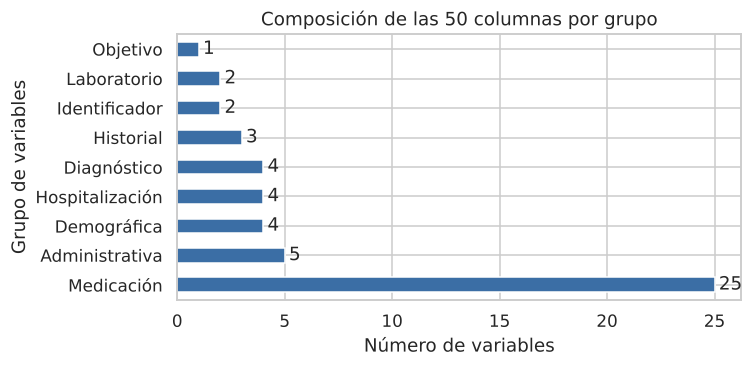

In [6]:
resumen_grupos = tabla.groupby("grupo")["variable"].count().sort_values(ascending=False)
ax = resumen_grupos.plot(kind="barh", color="#3b6ea5", figsize=(7, 3.5))
ax.set_xlabel("Número de variables"); ax.set_ylabel("Grupo de variables")
ax.set_title("Composición de las 50 columnas por grupo")
for i, v in enumerate(resumen_grupos.values):
    ax.text(v + 0.2, i, str(v), va="center")
plt.tight_layout(); plt.show()

### 3.1 Variable objetivo

,registros,%
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


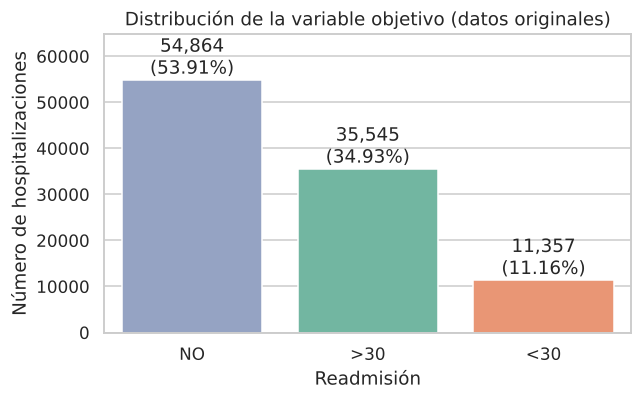

In [7]:
orden = ["NO", ">30", "<30"]
conteo = df_raw["readmitted"].value_counts().reindex(orden)
pct = (conteo / conteo.sum() * 100).round(2)
display(pd.DataFrame({"registros": conteo, "%": pct}))

fig, ax = plt.subplots(figsize=(6, 3.8))
sns.barplot(x=conteo.index, y=conteo.values, palette=["#8da0cb", "#66c2a5", "#fc8d62"], ax=ax)
for i, (c, p) in enumerate(zip(conteo.values, pct.values)):
    ax.text(i, c, f"{c:,}\n({p}%)", ha="center", va="bottom")
ax.set_xlabel("Readmisión"); ax.set_ylabel("Número de hospitalizaciones")
ax.set_title("Distribución de la variable objetivo (datos originales)")
ax.set_ylim(0, conteo.max() * 1.18)
plt.tight_layout(); plt.show()

### 3.2 Pacientes con múltiples hospitalizaciones

Cada fila es una **hospitalización**, no un paciente. Si un mismo paciente aparece en entrenamiento y en prueba, el modelo
puede "reconocerlo" y los resultados quedan inflados (**fuga de datos**). Además, las observaciones de un mismo paciente
no son independientes.

Hospitalizaciones: 101,766
Pacientes únicos: 71,518
Pacientes con más de una hospitalización: 16,773 (23.5%)
Máximo de hospitalizaciones de un paciente: 40


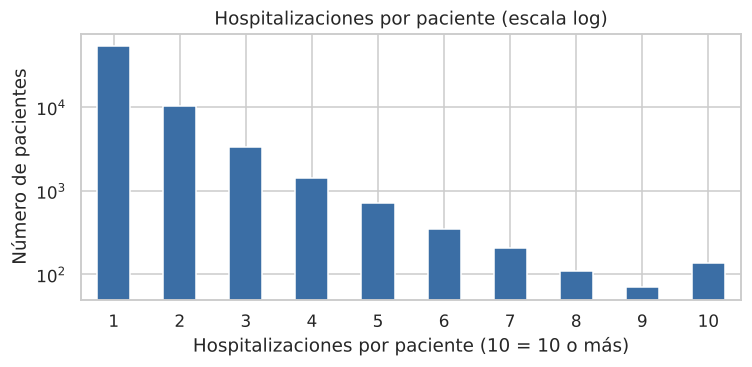

In [8]:
n_pac = df_raw["patient_nbr"].nunique()
visitas = df_raw.groupby("patient_nbr").size()
print(f"Hospitalizaciones: {len(df_raw):,}")
print(f"Pacientes únicos: {n_pac:,}")
print(f"Pacientes con más de una hospitalización: {(visitas > 1).sum():,} ({(visitas > 1).mean()*100:.1f}%)")
print(f"Máximo de hospitalizaciones de un paciente: {visitas.max()}")

fig, ax = plt.subplots(figsize=(7, 3.5))
visitas.clip(upper=10).value_counts().sort_index().plot(kind="bar", color="#3b6ea5", ax=ax)
ax.set_xlabel("Hospitalizaciones por paciente (10 = 10 o más)")
ax.set_ylabel("Número de pacientes"); ax.set_yscale("log")
ax.set_title("Hospitalizaciones por paciente (escala log)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 3.3 Datos faltantes

,% faltantes ('?')
weight,96.86
medical_specialty,49.08
payer_code,39.56
race,2.23
diag_3,1.40
diag_2,0.35
diag_1,0.02


,% exámenes no realizados
max_glu_serum (None = no medido),94.75
A1Cresult (None = no medido),83.28


,registros
gender = Unknown/Invalid,3
"admission_type_id sin info (5, 6, 8)",10396
"discharge_disposition_id sin info (18, 25, 26)",4680
"admission_source_id sin info (9, 15, 17, 20, 21)",7067


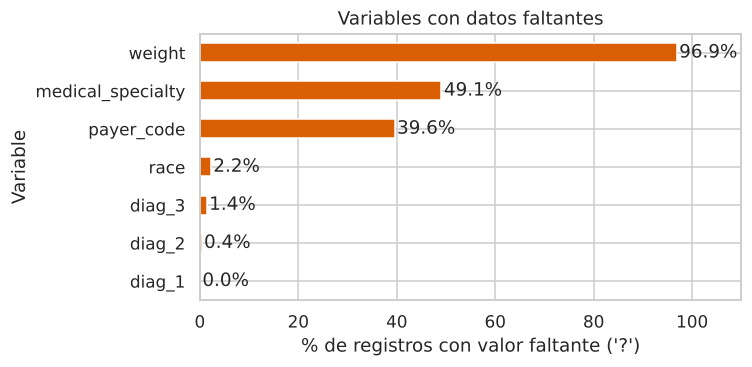

In [9]:
faltantes = (df_raw.isna().mean() * 100).sort_values(ascending=False)
faltantes = faltantes[faltantes > 0]

# Exámenes no realizados (no son faltantes, pero se reportan por transparencia)
no_medido = pd.Series({
    "max_glu_serum (None = no medido)": (df_raw["max_glu_serum"] == "None").mean() * 100,
    "A1Cresult (None = no medido)": (df_raw["A1Cresult"] == "None").mean() * 100})

# Valores inválidos o equivalentes a faltante en otras columnas
invalidos = pd.Series({
    "gender = Unknown/Invalid": (df_raw["gender"] == "Unknown/Invalid").sum(),
    "admission_type_id sin info (5, 6, 8)": df_raw["admission_type_id"].isin([5, 6, 8]).sum(),
    "discharge_disposition_id sin info (18, 25, 26)": df_raw["discharge_disposition_id"].isin([18, 25, 26]).sum(),
    "admission_source_id sin info (9, 15, 17, 20, 21)": df_raw["admission_source_id"].isin([9, 15, 17, 20, 21]).sum()})

display(faltantes.round(2).to_frame("% faltantes ('?')"))
display(no_medido.round(2).to_frame("% exámenes no realizados"))
display(invalidos.to_frame("registros"))

fig, ax = plt.subplots(figsize=(7, 3.5))
faltantes.plot(kind="barh", color="#d95f02", ax=ax)
for i, v in enumerate(faltantes.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.invert_yaxis(); ax.set_xlim(0, 110)
ax.set_xlabel("% de registros con valor faltante ('?')"); ax.set_ylabel("Variable")
ax.set_title("Variables con datos faltantes")
plt.tight_layout(); plt.show()

### 3.4 Variables numéricas

In [10]:
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
desc = df_raw[num_cols].describe().T
desc["asimetría"] = df_raw[num_cols].skew()
desc["% ceros"] = (df_raw[num_cols] == 0).mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría,% ceros
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0,1.13,0.00
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0,-0.24,0.00
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0,1.32,45.84
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0,1.33,0.00
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0,8.83,83.55
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0,22.86,88.81
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0,3.61,66.46
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0,-0.88,0.00


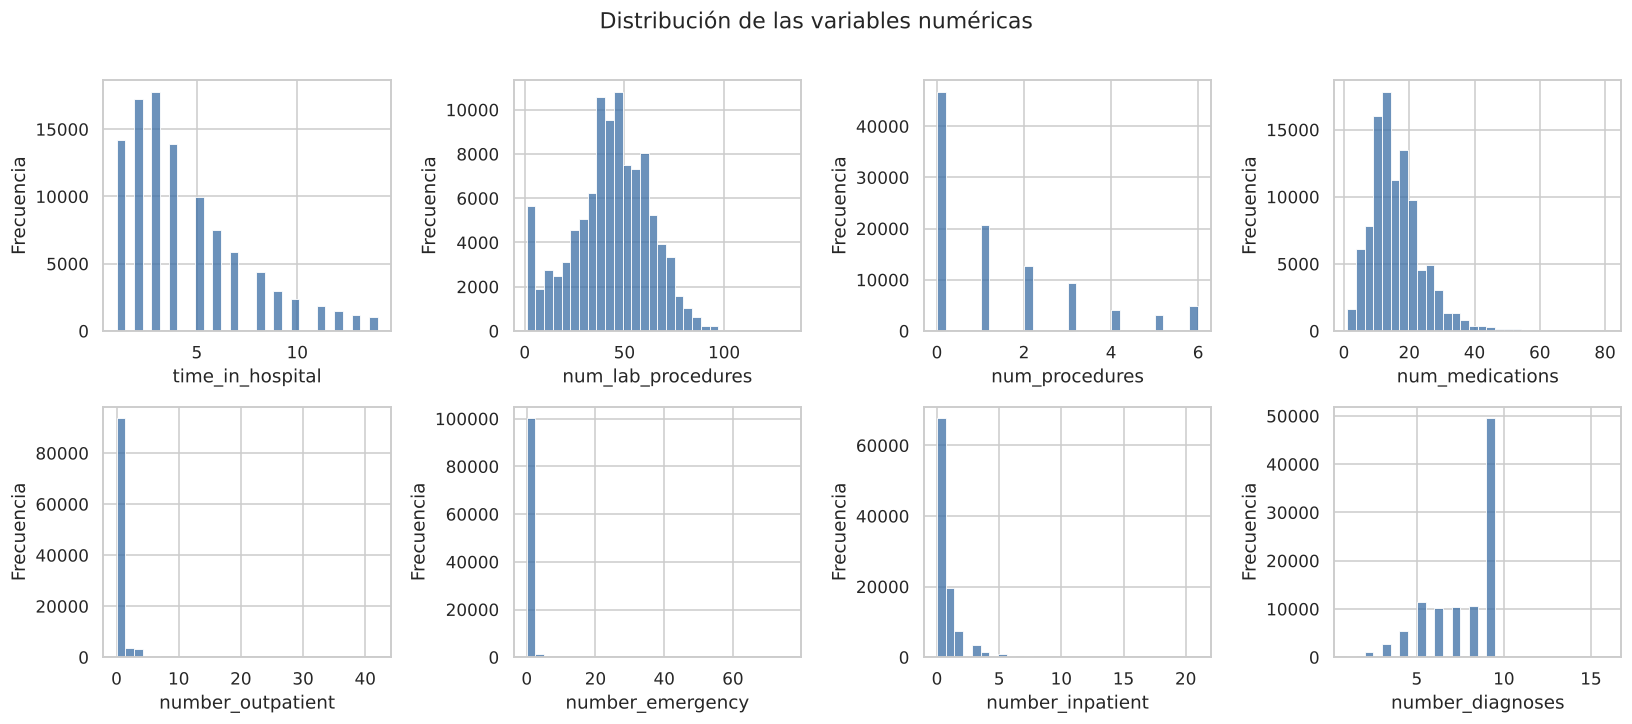

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df_raw[c], bins=30, ax=ax, color="#3b6ea5")
    ax.set_xlabel(c); ax.set_ylabel("Frecuencia")
fig.suptitle("Distribución de las variables numéricas", y=1.01)
plt.tight_layout(); plt.show()

Las variables de historial (`number_outpatient`, `number_emergency`, `number_inpatient`) son conteos muy asimétricos
con la mayoría de valores en cero. Esto sugiere una transformación `log1p` y escalado estándar para los modelos
sensibles a la escala (regresión logística, KNN, SVM, red neuronal).

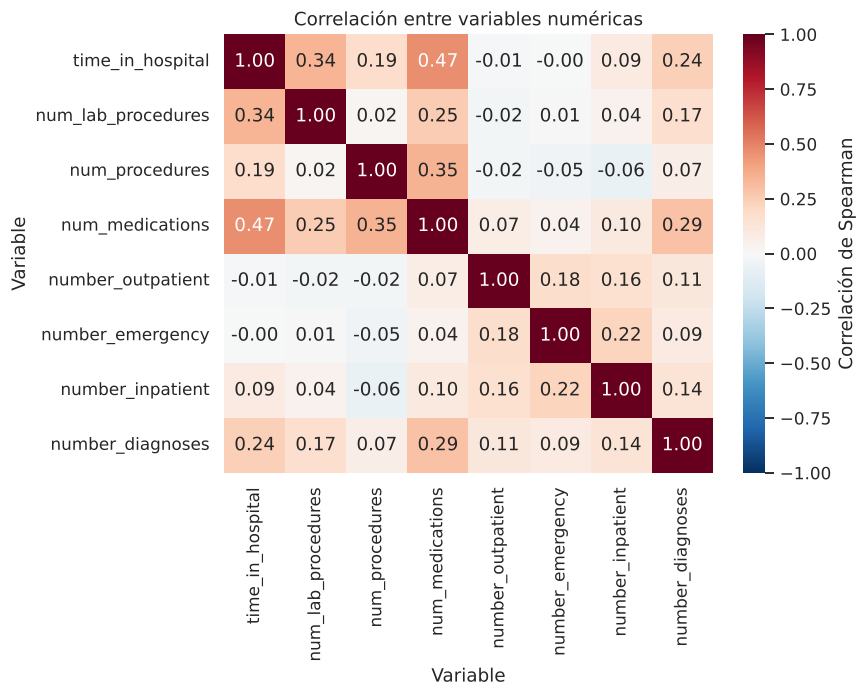

In [12]:
corr = df_raw[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Correlación de Spearman"})
ax.set_title("Correlación entre variables numéricas")
ax.set_xlabel("Variable"); ax.set_ylabel("Variable")
plt.tight_layout(); plt.show()

## 4. Limpieza y preprocesamiento

Decisiones tomadas (cada una justificada):

| # | Decisión | Justificación |
|---|---|---|
| 1 | Eliminar hospitalizaciones con alta a **fallecido u hospicio** (`discharge_disposition_id` ∈ {11, 13, 14, 19, 20, 21}) | Estos pacientes no pueden ser readmitidos; incluirlos sesga la clase negativa |
| 2 | Eliminar `gender = Unknown/Invalid` (3 registros) | Cantidad despreciable |
| 3 | Conservar **todas las hospitalizaciones** y usar `patient_nbr` como **grupo** en la validación | Las hospitalizaciones de un mismo paciente no son independientes. En lugar de conservar solo la primera (lo que elimina el 30 % de los datos y cambia la población), la validación por grupos (`StratifiedGroupKFold`) garantiza que un paciente nunca esté a la vez en entrenamiento y en validación/prueba. Esta decisión se comprueba experimentalmente en el notebook 2 (Experimento A) |
| 4 | Eliminar `weight` | 97 % de faltantes: no se puede imputar de forma confiable |
| 5 | Eliminar `payer_code` | ~40 % faltantes y sin relación clínica con la readmisión |
| 6 | `medical_specialty`: faltante → categoría **"Missing"**; se conservan las 10 especialidades más frecuentes y el resto → **"Other"** | El faltante es informativo (la especialidad no se registró); reducir cardinalidad evita cientos de columnas dummy |
| 7 | `race`: faltante → categoría **"Missing"** | ~2 % de faltantes; imputar con la moda introduciría sesgo |
| 8 | `diag_1/2/3`: agrupar los códigos ICD-9 en **9 categorías clínicas**; faltante → "Missing" | Más de 700 códigos distintos por columna; se usa la agrupación de Strack et al. (2014) |
| 9 | `admission_type_id`, `discharge_disposition_id`, `admission_source_id`: mapear a texto y agrupar | Son códigos nominales, no cantidades; los códigos "NULL / Not Mapped / Not Available" se unifican en "Unknown" |
| 10 | Eliminar `examide` y `citoglipton` | Constantes (un único valor) |
| 11 | Eliminar `encounter_id`; `patient_nbr` se guarda aparte como variable de grupo | Son identificadores: no se usan como predictores |
| 12 | Eliminar `diabetesMed` | Es redundante: equivale exactamente a `n_diab_meds > 0` (se verifica más abajo) |

In [13]:
df = df_raw.copy()
n0 = len(df)

# 1. Fallecidos / hospicio
excluir_alta = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(excluir_alta)]
n1 = len(df)

# 2. Género inválido
df = df[df["gender"] != "Unknown/Invalid"]
n2 = len(df)

# 3. Se conservan todas las hospitalizaciones; patient_nbr se usará como grupo en la validación
df = df.sort_values("encounter_id").reset_index(drop=True)
grupos = df["patient_nbr"].values

display(pd.DataFrame({
    "paso": ["Original", "Sin fallecidos/hospicio", "Sin género inválido"],
    "registros": [n0, n1, n2],
    "eliminados": [0, n0 - n1, n1 - n2]}))
visitas_dep = df.groupby("patient_nbr").size()
print(f"Pacientes: {df.patient_nbr.nunique():,} | con más de una hospitalización: {(visitas_dep > 1).mean()*100:.1f} % "
      f"| hospitalizaciones de pacientes repetidos: {(df.patient_nbr.map(visitas_dep) > 1).mean()*100:.1f} %")

# Comparación con la alternativa descartada (solo primera hospitalización por paciente)
primera = df.drop_duplicates("patient_nbr", keep="first")
print(f"Tasa <30 días: todas = {(df.readmitted == '<30').mean()*100:.2f} % | "
      f"solo primera = {(primera.readmitted == '<30').mean()*100:.2f} % ({len(primera):,} registros)")

,paso,registros,eliminados
0,Original,101766,0
1,Sin fallecidos/hospicio,99343,2423
2,Sin género inválido,99340,3


Pacientes: 69,987 | con más de una hospitalización: 23.3 % | hospitalizaciones de pacientes repetidos: 46.0 %
Tasa <30 días: todas = 11.39 % | solo primera = 8.98 % (69,987 registros)


In [14]:
# 4, 5, 10, 11. Columnas eliminadas
cols_drop = ["weight", "payer_code", "examide", "citoglipton", "encounter_id", "patient_nbr"]  # patient_nbr ya está en `grupos`
df = df.drop(columns=cols_drop)

# 6. Especialidad médica
df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
top_esp = df.loc[df["medical_specialty"] != "Missing", "medical_specialty"].value_counts().head(10).index
df["medical_specialty"] = np.where(df["medical_specialty"].isin(top_esp) | (df["medical_specialty"] == "Missing"),
                                   df["medical_specialty"], "Other")

# 7. Raza
df["race"] = df["race"].fillna("Missing")

print("Especialidades conservadas:", list(top_esp))
df["medical_specialty"].value_counts()

Especialidades conservadas: ['InternalMedicine', 'Emergency/Trauma', 'Family/GeneralPractice', 'Cardiology', 'Surgery-General', 'Nephrology', 'Orthopedics', 'Orthopedics-Reconstructive', 'Radiologist', 'Pulmonology']


medical_specialty
Missing                       48614
InternalMedicine              14237
Emergency/Trauma               7419
Other                          7345
Family/GeneralPractice         7252
Cardiology                     5278
Surgery-General                3059
Nephrology                     1539
Orthopedics                    1392
Orthopedics-Reconstructive     1230
Radiologist                    1121
Pulmonology                     854
Name: count, dtype: int64

### 4.1 Agrupación de diagnósticos ICD-9

| Grupo | Códigos ICD-9 |
|---|---|
| Circulatory | 390–459, 785 |
| Respiratory | 460–519, 786 |
| Digestive | 520–579, 787 |
| Diabetes | 250.xx |
| Injury | 800–999 |
| Musculoskeletal | 710–739 |
| Genitourinary | 580–629, 788 |
| Neoplasms | 140–239 |
| Other | Resto de códigos, incluidos los códigos V y E |

In [15]:
def grupo_icd9(codigo):
    if pd.isna(codigo):
        return "Missing"
    codigo = str(codigo)
    if codigo[0] in ("V", "E"):
        return "Other"
    x = float(codigo)
    if int(x) == 250:                               return "Diabetes"
    if 390 <= x <= 459 or int(x) == 785:            return "Circulatory"
    if 460 <= x <= 519 or int(x) == 786:            return "Respiratory"
    if 520 <= x <= 579 or int(x) == 787:            return "Digestive"
    if 800 <= x <= 999:                             return "Injury"
    if 710 <= x <= 739:                             return "Musculoskeletal"
    if 580 <= x <= 629 or int(x) == 788:            return "Genitourinary"
    if 140 <= x <= 239:                             return "Neoplasms"
    return "Other"

for c in ["diag_1", "diag_2", "diag_3"]:
    print(f"{c}: {df[c].nunique()} códigos distintos → ", end="")
    df[c] = df[c].map(grupo_icd9)
    print(f"{df[c].nunique()} grupos")

df["diag_1"].value_counts().to_frame("hospitalizaciones")

diag_1: 715 códigos distintos → 10 grupos
diag_2: 747 códigos distintos → 

10 grupos
diag_3: 786 códigos distintos → 

10 grupos


,hospitalizaciones
diag_1,
Circulatory,29680
Other,17793
Respiratory,13934
Digestive,9333
Diabetes,8661
Injury,6851
Genitourinary,5002
Musculoskeletal,4935
Neoplasms,3131


### 4.2 Agrupación de los códigos administrativos

In [16]:
adm_type = {1: "Emergency", 2: "Urgent", 3: "Elective", 7: "Emergency",   # 7 = Trauma Center
            4: "Unknown", 5: "Unknown", 6: "Unknown", 8: "Unknown"}   # 4 = Newborn (no aplica a esta población)

def grupo_alta(i):
    if i == 1:                   return "Home"
    if i in (6, 8):              return "Home health"
    if i == 7:                   return "Left AMA"
    if i in (18, 25, 26):        return "Unknown"
    # 9 y 12 (sigue hospitalizado / regresa como ambulatorio) son muy raros: se agrupan con traslados
    return "Transfer"            # traslados a otra institución

def grupo_fuente(i):
    if i in (1, 2, 3):                         return "Referral"
    if i == 7:                                 return "Emergency room"
    if i in (4, 5, 6, 10, 18, 22, 25, 26):     return "Transfer"
    if i in (9, 15, 17, 20, 21):               return "Unknown"
    return "Unknown"                           # códigos de neonatos u otros muy raros

df["admission_type"] = df["admission_type_id"].map(adm_type)
df["discharge_disposition"] = df["discharge_disposition_id"].map(grupo_alta)
df["admission_source"] = df["admission_source_id"].map(grupo_fuente)
df = df.drop(columns=["admission_type_id", "discharge_disposition_id", "admission_source_id"])

for c in ["admission_type", "discharge_disposition", "admission_source"]:
    print(df[c].value_counts().to_dict())

{'Emergency': 52387, 'Elective': 18667, 'Urgent': 18132, 'Unknown': 10154}
{'Home': 60232, 'Transfer': 20795, 'Home health': 13010, 'Unknown': 4680, 'Left AMA': 623}
{'Emergency room': 55848, 'Referral': 30433, 'Unknown': 6874, 'Transfer': 6185}


## 5. Paradigma de aprendizaje y variable objetivo

**Paradigma:** aprendizaje **supervisado**, tarea de **clasificación binaria**.

- **Clase positiva (1):** readmisión en **menos de 30 días** (`<30`).
- **Clase negativa (0):** readmisión después de 30 días (`>30`) o sin readmisión (`NO`).

**Justificación:**

- La readmisión a 30 días es el indicador clínico y regulatorio relevante (HRRP) y la formulación más usada en la
  literatura con este dataset, lo que facilita comparar resultados en la Sección 3.
- La clase `>30` se parece más a `NO` desde el punto de vista del objetivo práctico: identificar a quién intervenir antes
  del alta.

**Consecuencia:** el problema queda **desbalanceado**. Por eso:

- La exactitud (*accuracy*) no es una métrica adecuada; se usarán AUC-ROC, AUC-PR, F1, sensibilidad y *balanced accuracy*.
- Las particiones serán **estratificadas**.
- El balanceo (`class_weight` o sobremuestreo) se aplicará **solo dentro de los folds de entrenamiento**.

In [17]:
df["target"] = (df["readmitted"] == "<30").astype(int)
df = df.drop(columns=["readmitted"])

dist = df["target"].value_counts().sort_index()
display(pd.DataFrame({"registros": dist, "%": (dist / dist.sum() * 100).round(2)},
                     index=pd.Index([0, 1], name="target")).rename(index={0: "0 (NO / >30)", 1: "1 (<30)"}))
print(f"Razón de desbalance ≈ 1 : {dist[0] / dist[1]:.1f}")

,registros,%
target,,
0 (NO / >30),88026,88.61
1 (<30),11314,11.39


Razón de desbalance ≈ 1 : 7.8


## 6. Análisis bivariado: tasa de readmisión <30 días por variable

Cada barra indica el número de registros (`n`) de la categoría: las tasas de categorías con pocos registros no son confiables.

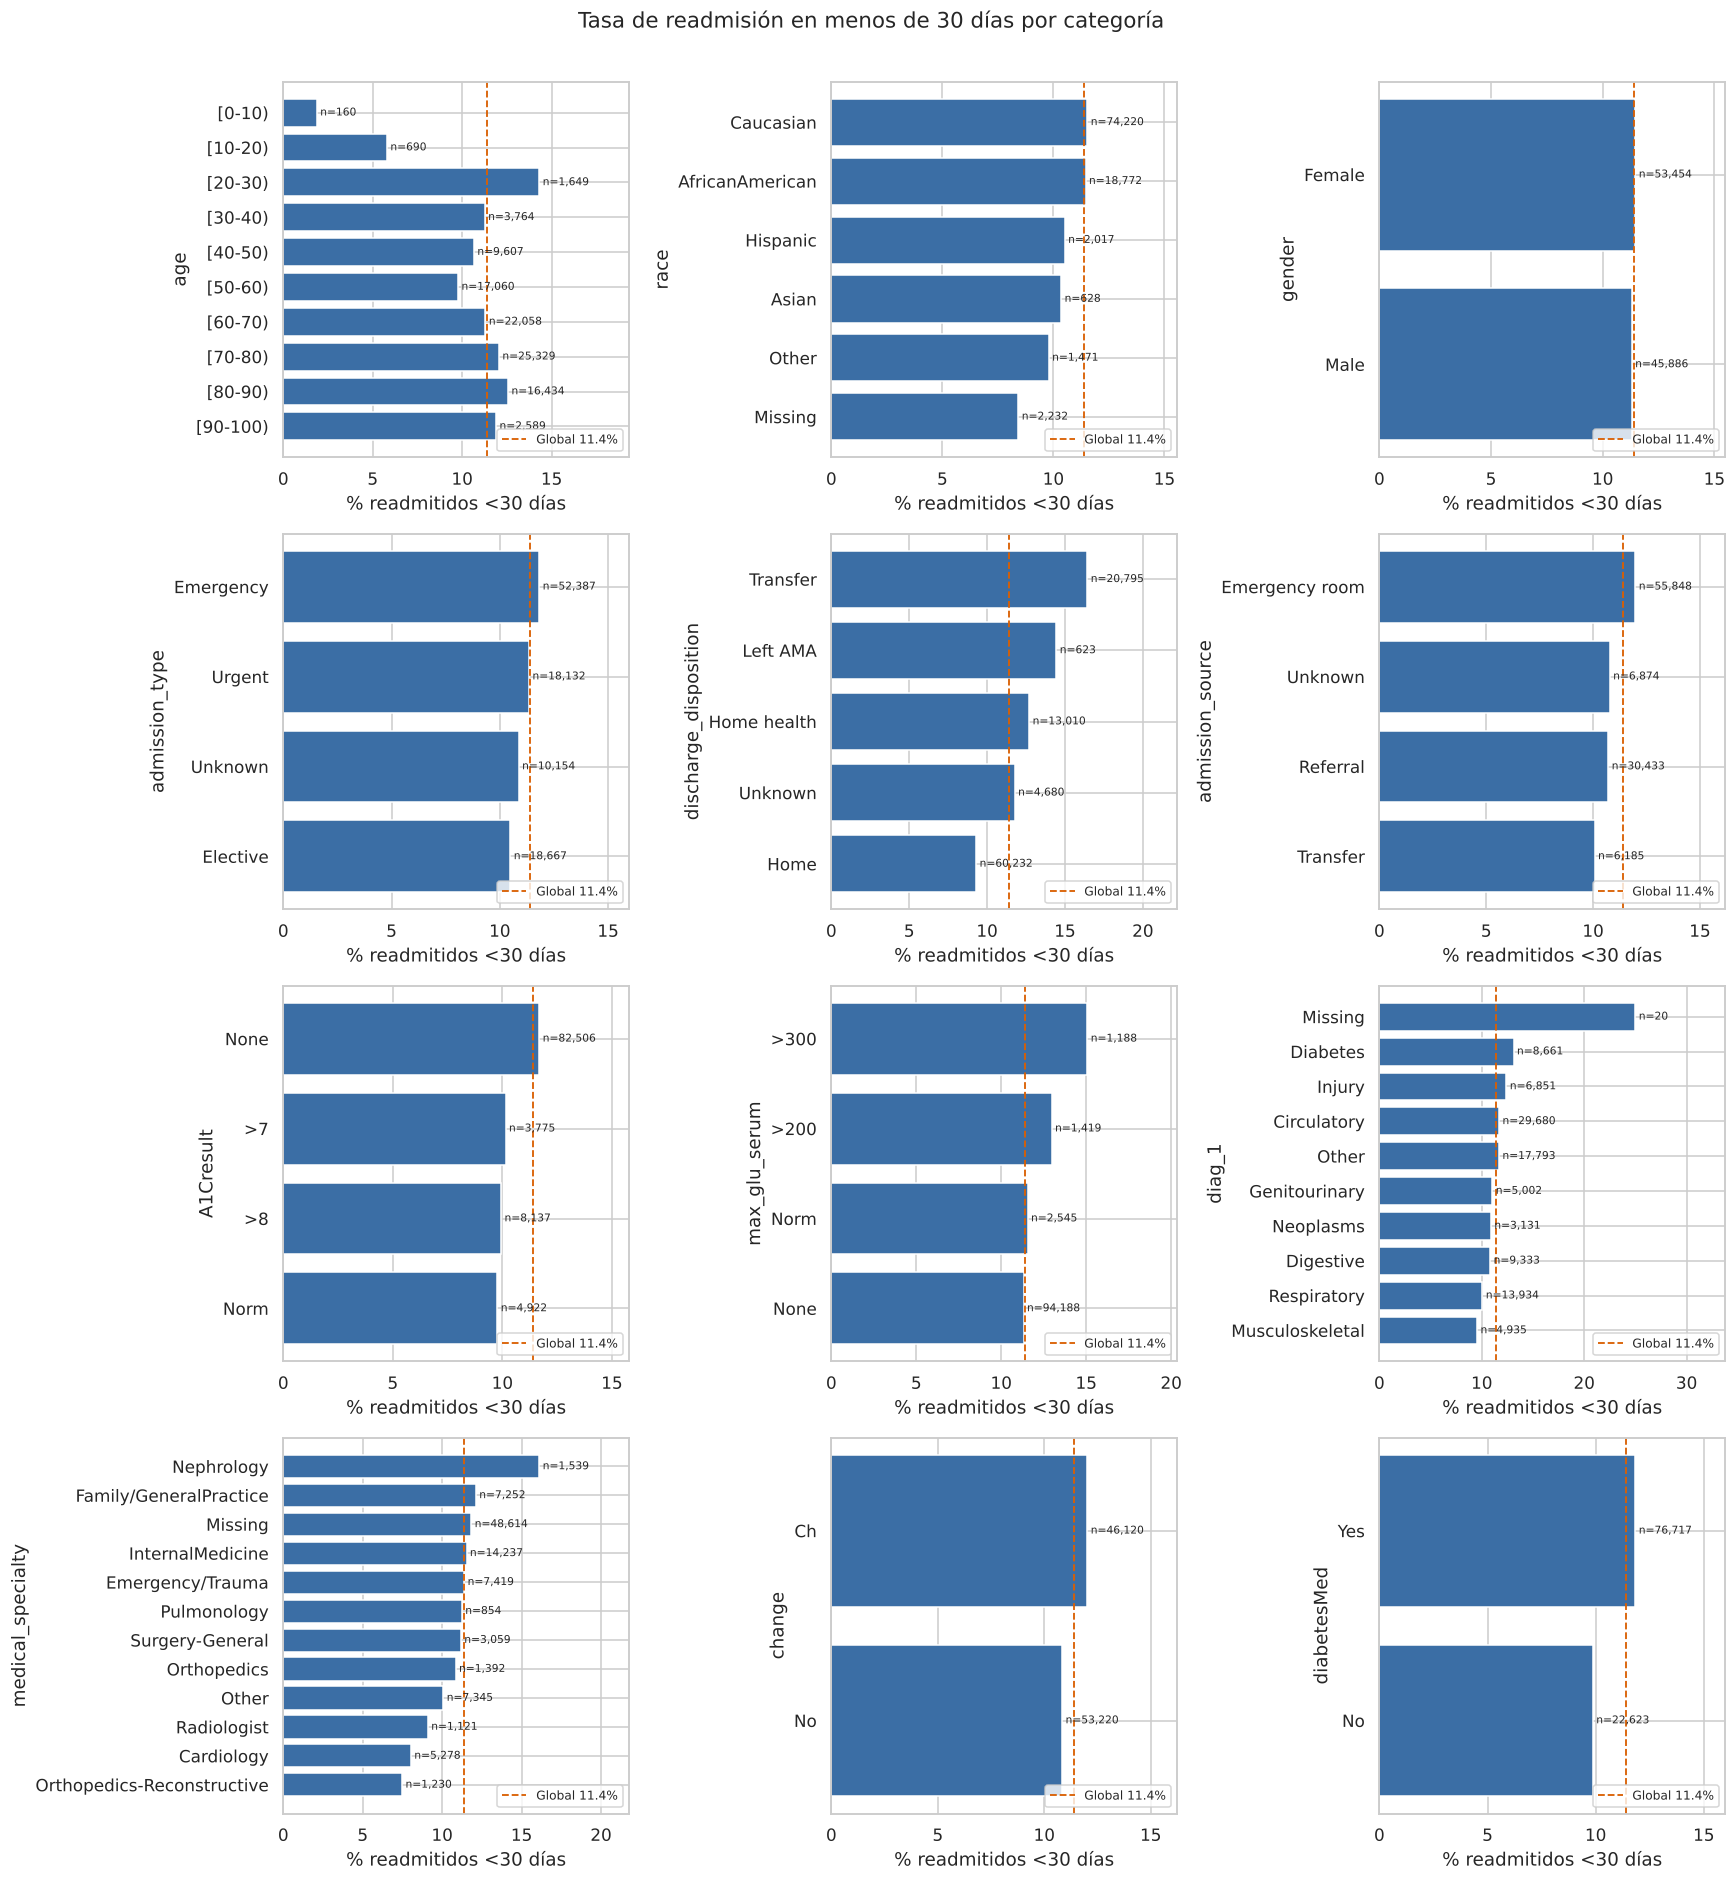

In [18]:
tasa_global = df["target"].mean() * 100

def graficar_tasa(col, ax, orden=None):
    t = df.groupby(col)["target"].agg(["mean", "size"])
    t["mean"] *= 100
    if orden is not None:
        t = t.reindex(orden)
    else:
        t = t.sort_values("mean", ascending=False)
    ax.barh(t.index.astype(str), t["mean"], color="#3b6ea5")
    for y, (v, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(v, y, f" n={n:,}", va="center", fontsize=7)
    ax.set_xlim(0, t["mean"].max() * 1.35)
    ax.axvline(tasa_global, color="#d95f02", ls="--", lw=1.2, label=f"Global {tasa_global:.1f}%")
    ax.invert_yaxis()
    ax.set_xlabel("% readmitidos <30 días"); ax.set_ylabel(col)
    ax.legend(fontsize=8, loc="lower right")

edades = sorted(df["age"].unique(), key=lambda s: int(re.findall(r"\d+", s)[0]))
cats = [("age", edades), ("race", None), ("gender", None), ("admission_type", None),
        ("discharge_disposition", None), ("admission_source", None), ("A1Cresult", None),
        ("max_glu_serum", None), ("diag_1", None), ("medical_specialty", None),
        ("change", None), ("diabetesMed", None)]

fig, axes = plt.subplots(4, 3, figsize=(16, 17))
for ax, (c, o) in zip(axes.ravel(), cats):
    graficar_tasa(c, ax, o)
fig.suptitle("Tasa de readmisión en menos de 30 días por categoría", y=1.005, fontsize=14)
plt.tight_layout(); plt.show()

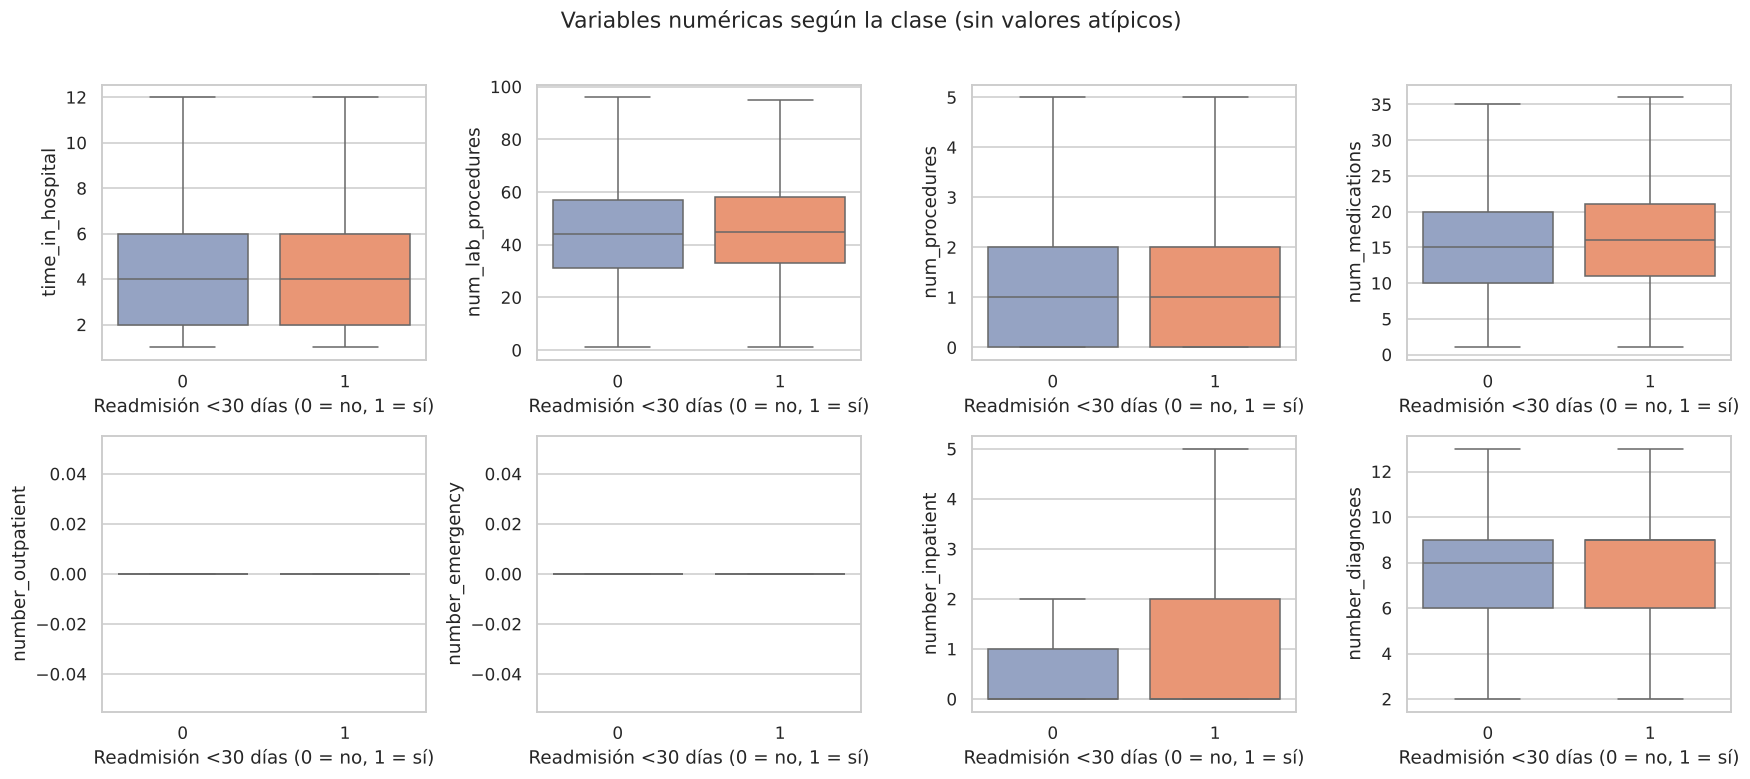

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="target", y=c, ax=ax, palette=["#8da0cb", "#fc8d62"], showfliers=False)
    ax.set_xlabel("Readmisión <30 días (0 = no, 1 = sí)"); ax.set_ylabel(c)
fig.suptitle("Variables numéricas según la clase (sin valores atípicos)", y=1.01)
plt.tight_layout(); plt.show()

**¿Por qué la prueba de Mann–Whitney?** Se quiere saber si cada variable numérica tiene una distribución distinta
en los dos grupos (readmitidos y no readmitidos). Son **dos grupos independientes** y las variables **no son
normales**: son conteos discretos, muy asimétricos y con muchos ceros (ver la tabla de asimetría y la prueba de
normalidad de D'Agostino abajo). En ese caso la prueba *t* de Student no es adecuada y se usa su alternativa no
paramétrica, Mann–Whitney *U*, que compara los rangos y no asume normalidad.

La prueba se usa solo de forma **descriptiva**: con ~99 000 registros casi cualquier diferencia resulta
"significativa", así que además del p-valor se reporta el **tamaño del efecto** $A = U/(n_0 n_1)$, que es la
probabilidad de que un readmitido tenga un valor mayor que un no readmitido (0,5 = sin diferencia). Coincide con el
AUC univariado de la variable.

In [20]:
res = []
for c in num_cols:
    a, b = df.loc[df.target == 0, c], df.loc[df.target == 1, c]
    u, p = stats.mannwhitneyu(b, a)
    res.append({"variable": c, "asimetría": round(stats.skew(df[c]), 2),
                "p normalidad (D'Agostino)": stats.normaltest(df[c]).pvalue,
                "mediana clase 0": a.median(), "mediana clase 1": b.median(),
                "p-valor Mann-Whitney": p, "efecto A = U/(n0·n1)": round(u / (len(a) * len(b)), 3)})
pd.DataFrame(res).sort_values("efecto A = U/(n0·n1)", ascending=False)

,variable,asimetría,p normalidad (D'Agostino),mediana clase 0,mediana clase 1,p-valor Mann-Whitney,efecto A = U/(n0·n1)
6,number_inpatient,3.63,0.000000e+00,0.0,0.0,0.000000e+00,0.607
0,time_in_hospital,1.14,0.000000e+00,4.0,4.0,1.587928e-62,0.548
7,number_diagnoses,-0.86,0.000000e+00,8.0,9.0,2.632621e-59,0.544
3,num_medications,1.34,0.000000e+00,15.0,16.0,9.394582e-52,0.544
5,number_emergency,22.85,0.000000e+00,0.0,0.0,1.244690e-91,0.532
1,num_lab_procedures,-0.24,1.842536e-280,44.0,45.0,2.910622e-14,0.522
4,number_outpatient,8.84,0.000000e+00,0.0,0.0,7.719281e-28,0.520
2,num_procedures,1.32,0.000000e+00,1.0,1.0,1.528420e-01,0.496


### 6.1 Medicamentos

In [21]:
meds_vivos = [m for m in meds if m in df.columns]
uso = pd.DataFrame({m: df[m].value_counts(normalize=True) * 100 for m in meds_vivos}).T.fillna(0)
uso = uso[["No", "Steady", "Up", "Down"]].sort_values("No")
uso["% usa"] = 100 - uso["No"]
display(uso.round(2))

casi_constantes = uso.index[uso["% usa"] < 0.1].tolist()
print("Medicamentos usados por menos del 0.1 % de los pacientes:", casi_constantes)

,No,Steady,Up,Down,% usa
insulin,46.68,30.27,11.06,11.99,53.32
metformin,80.03,18.33,1.07,0.58,19.97
glipizide,87.39,11.29,0.77,0.55,12.61
glyburide,89.41,9.22,0.81,0.56,10.59
pioglitazone,92.70,6.95,0.23,0.12,7.30
rosiglitazone,93.66,6.09,0.17,0.09,6.34
glimepiride,94.84,4.64,0.32,0.19,5.16
repaglinide,98.47,1.38,0.11,0.04,1.53
glyburide-metformin,99.30,0.69,0.01,0.01,0.70
nateglinide,99.31,0.66,0.02,0.01,0.69


Medicamentos usados por menos del 0.1 % de los pacientes: ['chlorpropamide', 'tolazamide', 'miglitol', 'tolbutamide', 'glipizide-metformin', 'troglitazone', 'metformin-rosiglitazone', 'acetohexamide', 'glimepiride-pioglitazone', 'metformin-pioglitazone']


Varios medicamentos son **casi constantes** (menos del 0.1 % de uso). Para no perder información, en lugar de
eliminarlos se crean dos variables resumen: **número de medicamentos para diabetes en uso** y **número de cambios de
dosis (Up/Down)**. Los medicamentos casi constantes se eliminan; los demás se mantienen con su codificación.

In [22]:
df["n_diab_meds"] = (df[meds_vivos] != "No").sum(axis=1)
df["n_dose_changes"] = df[meds_vivos].isin(["Up", "Down"]).sum(axis=1)
# diabetesMed es redundante con n_diab_meds: se verifica y se elimina
display(pd.crosstab(df["diabetesMed"], df["n_diab_meds"] > 0))
df = df.drop(columns="diabetesMed")
df = df.drop(columns=casi_constantes)
meds_final = [m for m in meds_vivos if m not in casi_constantes]
print(f"Medicamentos conservados ({len(meds_final)}):", meds_final)

n_diab_meds,False,True
diabetesMed,,
No,22623,0
Yes,0,76717


Medicamentos conservados (11): ['metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'insulin', 'glyburide-metformin']


## 7. Codificación de variables

| Tipo | Variables | Codificación |
|---|---|---|
| Numéricas continuas / conteos | `time_in_hospital`, `num_lab_procedures`, `num_procedures`, `num_medications`, `number_diagnoses`, `n_diab_meds`, `n_dose_changes` | Estandarización (media 0, desviación 1) |
| Conteos muy asimétricos | `number_outpatient`, `number_emergency`, `number_inpatient` | `log1p` + estandarización |
| Ordinal | `age` (10 rangos) | Entero 0–9 (punto medio del rango en décadas) |
| Ordinal | `A1Cresult` (None < Norm < >7 < >8), `max_glu_serum` (None < Norm < >200 < >300) | One-hot (porque "None" = no medido no es un nivel intermedio) |
| Binarias | `gender`, `change` | 0 / 1 |
| Nominales | `race`, `admission_type`, `discharge_disposition`, `admission_source`, `medical_specialty`, `diag_1/2/3` | One-hot |
| Medicamentos | No / Steady / Up / Down | One-hot |

Los modelos basados en árboles no necesitan el escalado, pero se usa el mismo preprocesamiento para todos por simplicidad
y reproducibilidad. **El escalado, la lista de especialidades frecuentes y la lista de medicamentos raros se ajustan
solo con los datos de entrenamiento de cada fold** en los notebooks de modelado (clase `Preprocesador`). En este
notebook se calculan con todos los datos únicamente con fines descriptivos.

In [23]:
df["age"] = df["age"].map(lambda s: int(re.findall(r"\d+", s)[0]) // 10)
df["gender"] = (df["gender"] == "Male").astype(int)
df["change"] = (df["change"] == "Ch").astype(int)
for c in ["number_outpatient", "number_emergency", "number_inpatient"]:
    df[c] = np.log1p(df[c])

cat_cols = ["race", "admission_type", "discharge_disposition", "admission_source", "medical_specialty",
            "diag_1", "diag_2", "diag_3", "A1Cresult", "max_glu_serum"] + meds_final
X_dummies = pd.get_dummies(df.drop(columns="target"), columns=cat_cols, drop_first=False, dtype=int)

print(f"Variables antes de codificar: {df.shape[1] - 1}")
print(f"Variables después de one-hot: {X_dummies.shape[1]}")
print(f"Registros finales: {len(df):,}")

Variables antes de codificar: 34
Variables después de one-hot: 126
Registros finales: 99,340


## 8. Resumen del dataset final y exportación

In [24]:
resumen = pd.DataFrame({
    "concepto": ["Hospitalizaciones originales", "Pacientes únicos originales", "Hospitalizaciones finales",
                 "Variables originales", "Variables tras limpieza (sin codificar)", "Variables tras one-hot",
                 "% clase positiva (<30 días)"],
    "valor": [f"{len(df_raw):,}", f"{df_raw.patient_nbr.nunique():,}", f"{len(df):,}",
              df_raw.shape[1] - 1, df.shape[1] - 1, X_dummies.shape[1],
              f"{df.target.mean()*100:.2f}%"]})
display(resumen)

salida = os.path.join(DATA_DIR, "diabetic_clean.csv")
df.to_csv(salida, index=False)
print("Dataset limpio (sin one-hot) guardado en:", salida)

,concepto,valor
0,Hospitalizaciones originales,"101,766"
1,Pacientes únicos originales,"71,518"
2,Hospitalizaciones finales,"99,340"
3,Variables originales,49
4,Variables tras limpieza (sin codificar),34
5,Variables tras one-hot,126
6,% clase positiva (<30 días),11.39%


Dataset limpio (sin one-hot) guardado en: /home/claude/proyecto/run/data_set/diabetic_clean.csv


## 9. Conclusiones del análisis exploratorio

Las cifras exactas aparecen en las salidas de las celdas anteriores. Los hallazgos principales son:

1. **Unidad de análisis.** El dataset tiene 101.766 hospitalizaciones de 71.518 pacientes. Tras la depuración quedan
   99.340 hospitalizaciones de 69.987 pacientes. Se conservan todas y la dependencia entre hospitalizaciones de un mismo
   paciente se controla con validación por grupos (`patient_nbr`), lo que evita la fuga de información sin descartar datos.
2. **Datos faltantes.** `weight` (~97 %) y `payer_code` (~40 %) se eliminaron. En `medical_specialty` (~49 %), `race` y los
   diagnósticos, el faltante se trató como una categoría propia ("Missing") en lugar de imputarlo.
3. **Falsos faltantes.** En los exámenes de laboratorio, "None" significa *no medido*; se conservó como categoría.
4. **Variable objetivo.** Se planteó como clasificación binaria (<30 días vs. resto), con un desbalance fuerte que
   condiciona la elección de métricas y la estrategia de validación.
5. **Señales predictivas.** Las variables con mayor diferencia entre clases son el historial de hospitalizaciones
   (`number_inpatient`), el destino al alta (los trasladados a otra institución se readmiten más), la estancia
   hospitalaria, la edad y el uso de medicación para diabetes. En general las diferencias
   son pequeñas (efecto A entre 0,50 y 0,61), lo que es coherente con los desempeños modestos (AUC ≈ 0.65–0.70) reportados en la literatura.
6. **Codificación.** Tras agrupar diagnósticos, códigos administrativos y especialidades, y aplicar one-hot, el espacio de
   características queda en unas 130 variables. Esto motiva la Sección 5 (reducción de dimensión).